In [41]:
from astropy import units as u
from astropy import time

import numpy as np
import math as math

from poliastro import iod
from poliastro.bodies import Body, Earth, Jupiter, Sun
from poliastro.ephem import Ephem
from poliastro.maneuver import Maneuver
from poliastro.twobody import Orbit
from poliastro.util import time_range

In [42]:
import plotly.io as pio

pio.renderers.default = "plotly_mimetype+notebook_connected"

In [43]:
from astropy.coordinates import solar_system_ephemeris

solar_system_ephemeris.set("jpl")

<ScienceState solar_system_ephemeris: 'jpl'>

In [44]:
# Initial data
date_launch = time.Time("2025-10-02 00:00", scale="utc").tdb
date_arrival = time.Time("2028-04-16 00:00", scale="utc").tdb

c:\src\ASEN5053\project\python\.conda\lib\site-packages\erfa\core.py:154: ErfaWarning:

ERFA function "dtf2d" yielded 1 of "dubious year (Note 6)"

c:\src\ASEN5053\project\python\.conda\lib\site-packages\erfa\core.py:154: ErfaWarning:

ERFA function "utctai" yielded 1 of "dubious year (Note 3)"

c:\src\ASEN5053\project\python\.conda\lib\site-packages\erfa\core.py:154: ErfaWarning:

ERFA function "taiutc" yielded 1 of "dubious year (Note 4)"



In [45]:
earth = Ephem.from_body(Earth, time_range(date_launch, end=date_arrival))
jupiter = Ephem.from_body(Jupiter, time_range(date_launch, end=date_arrival))
# Solve for departure and target orbits
ss_earth = Orbit.from_ephem(Sun, earth, date_launch)
ss_jupiter = Orbit.from_ephem(Sun, jupiter, date_arrival)

print(ss_earth.v/24/60/60)
print(ss_earth.r)
print(ss_jupiter.v/4/60/60)
print(ss_jupiter.r)



[-4.98939173 26.90635529 11.66228996] km / d
[1.47459042e+08 2.00348670e+07 8.70767252e+06] km
[ -8.00843255 -68.48082087 -29.15762411] km / d
[-8.09853889e+08  6.01657977e+07  4.55112138e+07] km


In [51]:
# Solve for the transfer maneuver
man_lambert = Maneuver.lambert(ss_earth, ss_jupiter)

# calculate dV magnitude
dv1_v = man_lambert.impulses[0][1]
dv2_v = man_lambert.impulses[1][1]
print (dv1_v)
print (dv2_v)
man_lambert.get_total_cost()

# Get the transfer and final orbits
ss_trans, ss_target = ss_earth.apply_maneuver(man_lambert, intermediate=True)

print(ss_trans.a)
print(ss_trans.ecc)

print(ss_target.a)
print(ss_target.ecc)

[1505.54224087 6974.21749411 6971.14983843] m / s
[  905.09155833 -5324.67541218 -1555.22029708] m / s
485553187.5220434 km
0.6941912189709125
777611424.6123877 km
0.04902777221957161


In [47]:
from poliastro.plotting import OrbitPlotter3D
plotter = OrbitPlotter3D()
plotter.set_attractor(Sun)

plotter.plot_ephem(earth, date_launch, label="Earth at launch position")
plotter.plot_ephem(jupiter, date_arrival, label="Jupiter at arrival position", color="purple")
plotter.plot_ephem(earth, date_arrival, label="Earth at arrival position")
plotter.plot_ephem(jupiter,date_launch,label="Jupiter at launch position", color="orange")
plotter.plot_trajectory(
    ss_trans.sample(max_anomaly=180 * u.deg),
    color="black",
    label="Transfer orbit",
)
plotter.set_view(45 * u.deg, 260 * u.deg, distance=3* u.km)

C:\Users\aussiebuttz\AppData\Local\Temp\ipykernel_26132\1577612030.py:10: DeprecationWarning:

Specifying min_anomaly and max_anomaly in method `sample` is deprecated and will be removed in a future release, use `Orbit.to_ephem(strategy=TrueAnomalyBounds(min_nu=..., max_nu=...))` instead



C:\Users\aussiebuttz\AppData\Local\Temp\ipykernel_26132\2429190484.py:19: DeprecationWarning:

Specifying min_anomaly and max_anomaly in method `sample` is deprecated and will be removed in a future release, use `Orbit.to_ephem(strategy=TrueAnomalyBounds(min_nu=..., max_nu=...))` instead



([<matplotlib.lines.Line2D at 0x1df2dacaa00>], None)

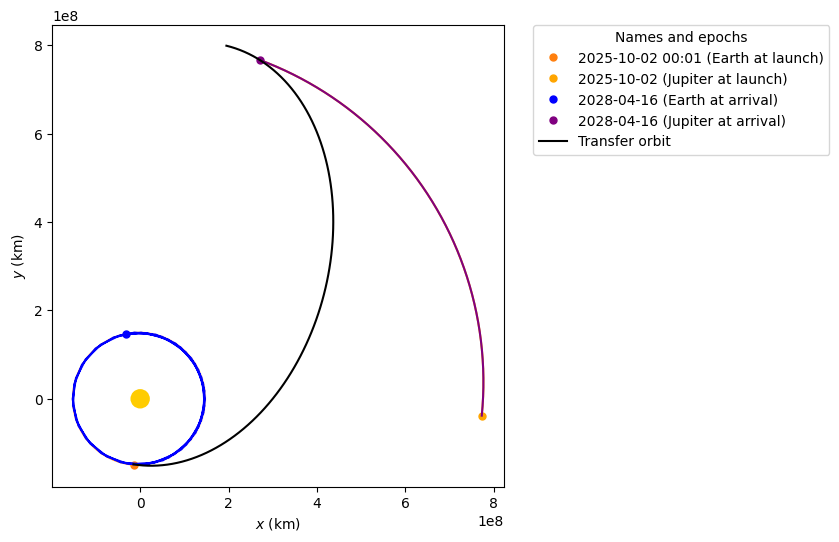

In [48]:
from poliastro.plotting import StaticOrbitPlotter

l1 = "Earth at launch (" + date_launch.strftime('%Y-%m-%d') + ")"
l2 = date_launch.strftime('%Y-%m-%d') + " (Jupiter at launch)"
l3 = date_arrival.strftime('%Y-%m-%d') + " (Earth at arrival)"
l4 = date_arrival.strftime('%Y-%m-%d') + " (Jupiter at arrival)"
plotter = StaticOrbitPlotter()
plotter.plot_body_orbit(
    Earth,
    date_launch,
    label="Earth at launch",
    color="C1",
    trail=True,
)
plotter.plot_ephem(jupiter,date_launch,label=l2, color="orange")
plotter.plot_ephem(earth, date_arrival, label=l3, color="blue")
plotter.plot_ephem(jupiter, date_arrival, label=l4, color="purple")
plotter.plot_trajectory(
    ss_trans.sample(max_anomaly=180 * u.deg),
    color="black",
    label="Transfer orbit",
)
# plotter.set_view(45 * u.deg, 260 * u.deg, distance=3* u.km)

In [61]:
# Jupiter to Europa transfer

from astropy.constants import Constant

my_mean_a_europa = Constant(
    "mean_a_europa",
    "My Europa's orbit mean semimajor axis around Jupiter",
    671100,
    "km",
    0,
    "NASA Planetary Satellite Mean Elements",
    system="si",
)

my_GM_europa = Constant(
    "GM_europa",
    "My Europa gravitational constant",
    3202.71210,
    "km3 / (s2)",
    0.00050,
    "NASA Planetary Satellite Physical Parameters",
    system="si",
)

Europa = Body(
    parent=Jupiter,
    k=my_GM_europa,
    name="Europa",
    mass=4.8e22,
    R=2560,
    rotational_period=3.551*24*60*60
)

craft_earth = Orbit.circular(Earth,400 *u.km,epoch=date_launch)

# calculate excess hyperbolic speed first impulse
print(ss_trans.a)
print(ss_trans.ecc)
print((craft_earth.v + ss_trans.v))


# Calculate excess hyperbolic speed second impulse
craft_jupiter = Orbit.circular(Jupiter,1000000 *u.km,epoch=date_arrival)
print(ss_target.a)
print(ss_target.ecc)
print((craft_jupiter.v + ss_target.v))




485553187.5220434 km
0.6941912189709125
[-3.48384949 41.54913119 18.63343979] km / s
777611424.6123877 km
0.04902777221957161
[-1.33473876 -0.5388095  -4.85960402] km / s
